# Notebook 02 — Preparación y modelado de datos (Fase 3)

**Qué hace este notebook:** limpia el dataset original, trata los valores atípicos, selecciona variables, define dimensiones y métricas y deja listo un archivo limpio (`data/processed/lineas_limpias.parquet`) que usan los notebooks 03, 04 y 05 y el dashboard.

**Principio de trabajo:** cada regla de limpieza se justifica por una razón de negocio y se registra cuántas filas elimina, para que cualquiera pueda auditar la decisión.

In [1]:
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Rutas del proyecto (los notebooks viven en /notebooks)
RAIZ = Path('..').resolve()
RAW = RAIZ / 'data' / 'raw' / 'online_retail_II.csv'
PROC = RAIZ / 'data' / 'processed'
FIG = RAIZ / 'docs' / 'figuras'
PROC.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

# Estilo comun a todos los graficos del proyecto
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.figsize': (9, 4.5), 'axes.titleweight': 'bold',
                     'axes.spines.top': False, 'axes.spines.right': False})
AZUL, NARANJA, GRIS, VERDE = '#1F4E79', '#E8833A', '#8C8C8C', '#3B8E5A'
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

## 1. Carga y renombrado

Se renombran las columnas a `snake_case` para evitar el espacio de `Customer ID` y facilitar el código.

In [2]:
raw = pd.read_csv(RAW, parse_dates=['InvoiceDate'],
                  dtype={'Invoice': 'string', 'StockCode': 'string'})
df = raw.rename(columns={
    'Invoice': 'factura', 'StockCode': 'codigo', 'Description': 'descripcion',
    'Quantity': 'cantidad', 'InvoiceDate': 'fecha_hora', 'Price': 'precio',
    'Customer ID': 'cliente_id', 'Country': 'pais'})
df['es_cancelacion'] = df['factura'].str.startswith('C')
print(f'{len(df):,} filas cargadas')
df.head(3)

1,067,371 filas cargadas


,factura,codigo,descripcion,cantidad,fecha_hora,precio,cliente_id,pais,es_cancelacion
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom,False
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,False
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,False


## 2. Reglas de limpieza (en este orden)

| # | Regla | Por qué |
|---|---|---|
| R1 | Eliminar líneas **duplicadas exactas** | Mismo pedido, producto, cantidad, precio y hora: son registros repetidos y inflan las ventas |
| R2 | Eliminar **códigos que no son productos** (envío, comisiones, ajustes, pruebas) | No son ventas de mercancía; distorsionan precio medio y ticket |
| R3 | Eliminar **precio ≤ 0** | Son ajustes contables o regalos sin valor de venta |
| R4 | Eliminar **cantidad ≤ 0 que no sea cancelación** | Mercancía dañada o ajustes de inventario, no ventas ni devoluciones de clientes |

**Lo que NO se elimina:** las **cancelaciones** (factura con `C`): son devoluciones reales y las necesitamos para medir la tasa de devolución. Tampoco se eliminan las líneas **sin cliente** (≈15 % del ingreso): sirven para los KPIs de ventas, solo se excluyen de los análisis *por cliente*.

In [3]:
patron_producto = r'^\d{5}|^DCGS|^gift_'
registro = [{'regla': 'Dataset original', 'filas_restantes': len(df), 'filas_eliminadas': 0}]

def aplicar(nombre, mascara_conservar, datos):
    out = datos[mascara_conservar]
    registro.append({'regla': nombre, 'filas_restantes': len(out),
                     'filas_eliminadas': len(datos) - len(out)})
    return out

d1 = aplicar('R1 duplicados exactos', ~df.duplicated(), df)
d2 = aplicar('R2 codigos que no son producto', d1['codigo'].str.match(patron_producto), d1)
d3 = aplicar('R3 precio <= 0', d2['precio'] > 0, d2)
d4 = aplicar('R4 cantidad <= 0 sin ser cancelacion',
             (d3['cantidad'] > 0) | d3['es_cancelacion'], d3)

reglas = pd.DataFrame(registro)
reglas['% eliminado del original'] = (reglas['filas_eliminadas'] / len(df) * 100).round(2)
reglas

,regla,filas_restantes,filas_eliminadas,% eliminado del original
0,Dataset original,1067371,0,0.00
1,R1 duplicados exactos,1033036,34335,3.22
2,R2 codigos que no son producto,1027313,5723,0.54
3,R3 precio <= 0,1021330,5983,0.56
4,R4 cantidad <= 0 sin ser cancelacion,1021330,0,0.00


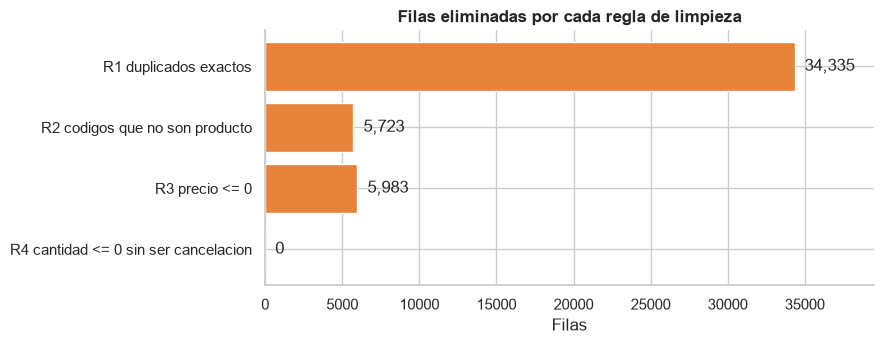

Filas finales: 1,021,330 (95.7% del original)


In [4]:
fig, ax = plt.subplots(figsize=(9, 3.6))
r = reglas.iloc[1:]
ax.barh(r['regla'][::-1], r['filas_eliminadas'][::-1], color=NARANJA)
for i, v in enumerate(r['filas_eliminadas'][::-1]):
    ax.text(v, i, f'  {v:,}', va='center')
ax.set_title('Filas eliminadas por cada regla de limpieza')
ax.set_xlabel('Filas')
ax.set_xlim(0, r['filas_eliminadas'].max() * 1.15)
plt.tight_layout()
plt.savefig(FIG / '02_limpieza_filas_por_regla.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Filas finales: {len(d4):,} ({len(d4)/len(df):.1%} del original)')

**Lectura de la tabla de reglas.**
- R1 (duplicados) es la regla que más elimina: **34.335 líneas (3,2 % del original)**.
- R2 y R3 eliminan 5.723 y 5.983 líneas (≈ 0,5 % cada una).
- **R4 eliminó 0 filas adicionales:** las líneas con cantidad ≤ 0 que no eran cancelaciones ya tenían precio 0, así que R3 las había quitado. Se deja la regla en el código como *verificación*: confirma que no queda ninguna cantidad negativa fuera de las devoluciones.
- Quedan **1.021.330 líneas (95,7 % del original)**: se limpió poco, lo que indica que la fuente es de buena calidad.